# ColdChain AI — Temperature Excursion Prediction System
**Subject:** Data Science-I (Term Work) &nbsp;|&nbsp; **Team:** Hiren Patel (Roll 68), Zeeshan Ansari (Roll 70)

**Aim:** a cold storage room must stay between 2°C and 8°C. We built an ML system that:
1. **Regression** — predicts the room temperature of the next hour
2. **Classification** — predicts whether the next hour will be a temperature excursion (below 2°C or above 8°C)

**Steps in this notebook** (each step in its own cell):
1. Make the sensor data → 2. EDA → 3. Feature engineering → 4. Train/test setup →
5. Regression models → 6. Classification models → 7. Results → 8. Final plots

All models are strictly from the Data Science-I syllabus (25MCA3001).

In [1]:
%matplotlib inline
import ast
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.svm import SVR, SVC
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
                             accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix)
print("imports ok")

imports ok


## Step 1 — Make the sensor data
We don't have a real cold room, so we simulate one: 120 days of hourly readings (2880 rows).
The simulation follows simple rules — a day/night temperature cycle, door openings letting warm
air in, power cuts stopping the cooling, and rare thermostat faults that overcool the room.

In [2]:
np.random.seed(42)  # same data every time we run

HOURS = 120 * 24  # 120 days of hourly readings
t = np.arange(HOURS)

# --- base signals ---
hour_of_day = t % 24
# room temp moves a little with day/night cycle (base 4 deg)
base_temp = 4.0 + 0.8 * np.sin(2 * np.pi * hour_of_day / 24)
# outside (ambient) temp: hot afternoons, cool nights
ambient = 28 + 7 * np.sin(2 * np.pi * (hour_of_day - 9) / 24)

# door open minutes in that hour: mostly small, sometimes long
door_open = np.random.poisson(4, HOURS).astype(float)
long_open = np.random.rand(HOURS) < 0.12
door_open[long_open] = np.random.uniform(10, 40, long_open.sum())

# power problem in that hour (1 = fluctuation / cut).
# Power cuts last a few hours: if bad now, 55% chance it stays bad next hour.
power_bad = np.zeros(HOURS, dtype=int)
power_bad[0] = 1 if np.random.rand() < 0.08 else 0
for i in range(1, HOURS):
    if power_bad[i - 1] == 1:
        power_bad[i] = 1 if np.random.rand() < 0.55 else 0
    else:
        power_bad[i] = 1 if np.random.rand() < 0.045 else 0

# storage load % (how full the room is)
load = np.clip(np.random.normal(65, 12, HOURS), 30, 98)

# compressor on/off (off during power problem)
compressor = 1 - power_bad

# rare thermostat fault: cooling stuck ON -> room overcools for a few hours.
# This gives us some below-2C excursions too (not only heat).
fault = np.zeros(HOURS, dtype=int)
fault[0] = 1 if np.random.rand() < 0.02 else 0
for i in range(1, HOURS):
    if fault[i - 1] == 1:
        fault[i] = 1 if np.random.rand() < 0.5 else 0
    else:
        fault[i] = 1 if np.random.rand() < 0.012 else 0
print("base signals ready:", HOURS, "hours")

base signals ready: 2880 hours


In [3]:
# --- build inside temp from the signals ---
# A cold room has thermal inertia: temp changes slowly, so this hour's temp
# depends on last hour's temp too. Door open lets warm air in, power cut
# stops cooling.
temp = np.zeros(HOURS)
temp[0] = 4.0
for i in range(1, HOURS):
    target = (base_temp[i]
              + 0.28 * door_open[i]       # warm air in
              + 5.0 * power_bad[i]        # no cooling
              - 6.0 * fault[i]            # thermostat fault: overcooling
              + 0.03 * (ambient[i] - 28)  # hot day leaks in a bit
              - 0.01 * (load[i] - 65))    # full room stays cooler
    temp[i] = 0.60 * temp[i - 1] + 0.40 * target + np.random.normal(0, 0.3)

# humidity rises when door is open
humidity = np.clip(70 + 0.5 * door_open + np.random.normal(0, 3, HOURS),
                   55, 95)

df = pd.DataFrame({
    "hour": hour_of_day,
    "day": (t // 24) % 7,          # 0 = monday ... 6 = sunday
    "temp": np.round(temp, 2),
    "humidity": np.round(humidity, 1),
    "door_open_min": np.round(door_open, 1),
    "power_bad": power_bad,
    "load_pct": np.round(load, 1),
    "compressor_on": compressor,
    "ambient_temp": np.round(ambient, 1),
})

# regression target: temp in the NEXT hour
df["temp_next"] = df["temp"].shift(-1)
# classification target: 1 if temp goes out of safe range 2-8 deg
df["excursion"] = ((df["temp_next"] < 2.0) | (df["temp_next"] > 8.0)).astype(int)
df = df.dropna().reset_index(drop=True)

df.to_csv("data/coldchain.csv", index=False)
print("rows:", len(df))
print("excursion rate: %.2f %%" % (100 * df["excursion"].mean()))
df.head()

rows: 2879
excursion rate: 14.07 %


   hour  day  temp  humidity  ...  compressor_on  ambient_temp  temp_next  excursion
0     0    0  4.00      71.8  ...              1          23.1       4.41          0
1     1    0  4.41      77.3  ...              1          21.9       5.95          0
2     2    0  5.95      79.6  ...              1          21.2       9.31          1
3     3    0  9.31      85.5  ...              1          21.0       7.88          0
4     4    0  7.88      73.2  ...              1          21.2       7.10          0

[5 rows x 11 columns]

## Step 2 — EDA: first look at the data
Before modelling, we check the data: how many rows, any missing values, basic stats,
and which columns move together with our two targets.

In [4]:
df = pd.read_csv("data/coldchain.csv")
print("shape:", df.shape)
print("\nmissing values:\n", df.isnull().sum())
print("\ndescribe:\n", df.describe().round(2))
corr = df.corr(numeric_only=True)
print("\ncorr with temp_next:\n", corr["temp_next"].sort_values(ascending=False).round(3))
print("\ncorr with excursion:\n", corr["excursion"].sort_values(ascending=False).round(3))

shape: (2879, 11)

missing values:
 hour             0
day              0
temp             0
humidity         0
door_open_min    0
power_bad        0
load_pct         0
compressor_on    0
ambient_temp     0
temp_next        0
excursion        0
dtype: int64

describe:
           hour      day     temp  ...  ambient_temp  temp_next  excursion
count  2879.00  2879.00  2879.00  ...       2879.00    2879.00    2879.00
mean     11.50     2.98     6.10  ...         28.00       6.10       0.14
std       6.92     2.01     1.65  ...          4.96       1.65       0.35
min       0.00     0.00    -1.06  ...         21.00      -1.06       0.00
25%       5.50     1.00     5.08  ...         23.10       5.08       0.00
50%      11.00     3.00     5.80  ...         28.00       5.80       0.00
75%      17.00     5.00     6.90  ...         32.90       6.90       0.00
max      23.00     6.00    13.59  ...         35.00      13.59       1.00

[8 rows x 11 columns]

corr with temp_next:
 temp_next        1

plots saved in results/  (also shown above)


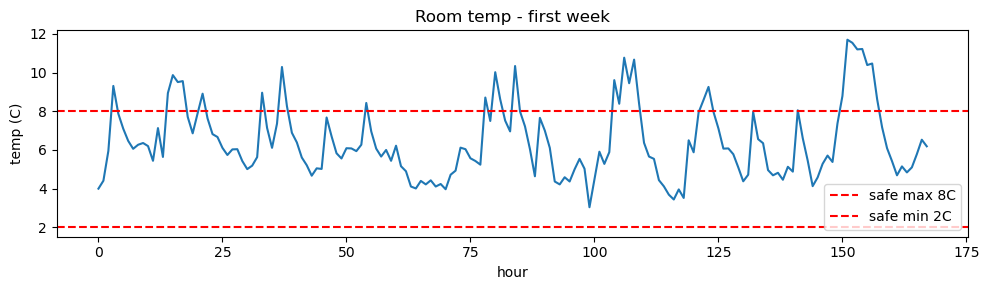

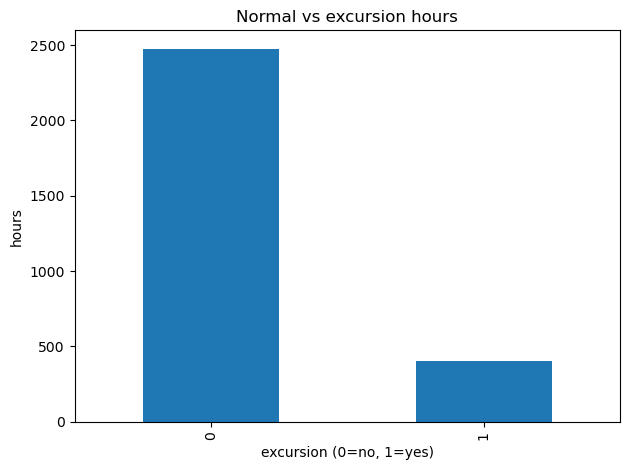

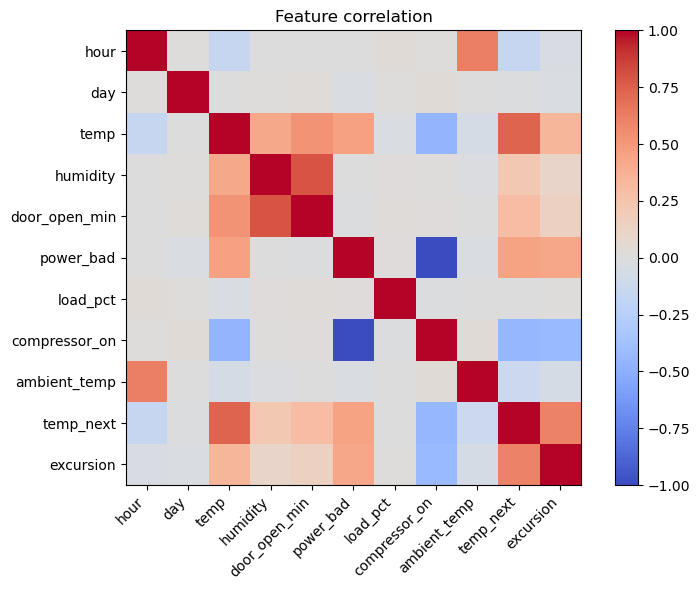

In [5]:
# 1. temp over first 7 days
plt.figure(figsize=(10, 3))
plt.plot(df["temp"][:168])
plt.axhline(8, color="r", ls="--", label="safe max 8C")
plt.axhline(2, color="r", ls="--", label="safe min 2C")
plt.title("Room temp - first week")
plt.xlabel("hour"); plt.ylabel("temp (C)"); plt.legend()
plt.tight_layout(); plt.savefig("results/temp_week.png")

# 2. excursion count
plt.figure()
ax = df["excursion"].value_counts().plot(kind="bar")
plt.title("Normal vs excursion hours")
plt.xlabel("excursion (0=no, 1=yes)"); plt.ylabel("hours")
plt.tight_layout(); plt.savefig("results/excursion_bar.png")

# 3. correlation heatmap
plt.figure(figsize=(8, 6))
corr = df.corr(numeric_only=True)
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
plt.yticks(range(len(corr)), corr.columns)
plt.title("Feature correlation")
plt.colorbar(); plt.tight_layout()
plt.savefig("results/corr.png")
print("plots saved in results/  (also shown above)")

## Step 3 — Feature engineering
The past helps predict the future, so we add: what the room looked like 1–2 hours ago
(lag features), the 3-hour average temperature (rolling mean), and the hour of day as a
circle (sin/cos — because 23:00 and 00:00 are neighbours, not far apart).
We drop `hour`, `day` and `compressor_on` (it is exactly 1 − power_bad, so it adds nothing).

In [6]:
df = pd.read_csv("data/coldchain.csv")

# cyclic encoding of hour of day
df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)

# what the room looked like 1 and 2 hours ago
for lag in [1, 2]:
    df[f"temp_lag{lag}"] = df["temp"].shift(lag)
    df[f"door_lag{lag}"] = df["door_open_min"].shift(lag)
    df[f"power_lag{lag}"] = df["power_bad"].shift(lag)

# average temp of last 3 hours (smooths sensor noise)
df["temp_roll3"] = df["temp"].rolling(3).mean()

df = df.drop(columns=["hour", "day", "compressor_on"])
df = df.dropna().reset_index(drop=True)
df.to_csv("data/coldchain_feat.csv", index=False)
print("shape after feature engineering:", df.shape)
print("columns:", list(df.columns))

shape after feature engineering: (2877, 17)
columns: ['temp', 'humidity', 'door_open_min', 'power_bad', 'load_pct', 'ambient_temp', 'temp_next', 'excursion', 'hour_sin', 'hour_cos', 'temp_lag1', 'door_lag1', 'power_lag1', 'temp_lag2', 'door_lag2', 'power_lag2', 'temp_roll3']


## Step 4 — Train/test setup: no shuffling!
This is time data, so we do NOT shuffle: the first 80% of hours are training, the last 20% are testing.
For cross-validation we use TimeSeriesSplit — the model never trains on the future and tests on the past.
KNN and Naive Bayes have no class_weight option, so for them we oversample the minority class —
but ONLY inside each CV fold, never before the split, so the scores stay honest.

In [7]:
df = pd.read_csv("data/coldchain_feat.csv")
X = df.drop(columns=["temp_next", "excursion"])
print("features:", list(X.columns))

tscv = TimeSeriesSplit(n_splits=5)
rows = []

# chronological split: no shuffling for time data
def chrono_split(X, y, frac=0.8):
    n = int(len(X) * frac)
    return (X.iloc[:n], X.iloc[n:], y.iloc[:n], y.iloc[n:])

# random oversampling of the minority class (for models like KNN and
# NaiveBayes that have no class_weight option, so the comparison stays fair)
def oversample(Xtr, ytr):
    rng = np.random.RandomState(42)
    pos = np.where(ytr == 1)[0]
    need = (ytr == 0).sum() - len(pos)
    extra = rng.choice(pos, size=need, replace=True)
    idx = np.concatenate([np.arange(len(ytr)), extra])
    rng.shuffle(idx)
    return Xtr.iloc[idx].reset_index(drop=True), ytr.iloc[idx].reset_index(drop=True)

print("setup ready: TimeSeriesSplit(5), chrono_split, oversample")

features: ['temp', 'humidity', 'door_open_min', 'power_bad', 'load_pct', 'ambient_temp', 'hour_sin', 'hour_cos', 'temp_lag1', 'door_lag1', 'power_lag1', 'temp_lag2', 'door_lag2', 'power_lag2', 'temp_roll3']
setup ready: TimeSeriesSplit(5), chrono_split, oversample


## Step 5 — Task 1 (regression): predict the next hour's temperature
First a dumb baseline: predict that the next hour = this hour (persistence).
Every real model must beat it. Winner = lowest RMSE on the test set.

In [8]:
print("===== TASK 1: regression -> temp_next =====")
y_reg = df["temp_next"]
Xtr, Xte, ytr, yte = chrono_split(X, y_reg)

# naive baseline: next hour = this hour (true persistence).
base_pred = Xte["temp"]
base_rmse = mean_squared_error(yte, base_pred) ** 0.5
print(f"Baseline (persistence)  RMSE={base_rmse:.4f}")
rows.append({"task": "regression", "model": "Baseline-persistence",
             "best_params": "-", "rmse": round(base_rmse, 4),
             "mae": round(mean_absolute_error(yte, base_pred), 4),
             "r2": round(r2_score(yte, base_pred), 4),
             "accuracy": "", "precision": "", "recall": "", "f1": "",
             "time_s": 0})

===== TASK 1: regression -> temp_next =====
Baseline (persistence)  RMSE=1.1540


### Step 5b — train the regression models
Linear Regression is fit directly (it has no hyperparameters — a fake grid search would be dishonest).
The rest are tuned with GridSearchCV / RandomizedSearchCV using TimeSeriesSplit.

In [9]:
reg_models = {
    "LinearRegression": ("direct", LinearRegression()),
    "KNNRegressor": ("grid", Pipeline([("s", StandardScaler()), ("m", KNeighborsRegressor())]),
                     {"m__n_neighbors": [3, 5, 9, 15, 25, 35]}),
    "DecisionTreeReg": ("grid", DecisionTreeRegressor(random_state=42),
                        {"max_depth": [3, 5, 8, 12, None],
                         "min_samples_split": [2, 5, 10]}),
    "RandomForestReg": ("random", RandomForestRegressor(random_state=42),
                        {"n_estimators": [50, 100, 200],
                         "max_depth": [5, 10, 15, None],
                         "min_samples_split": [2, 5]}),
    "SVR": ("grid", Pipeline([("s", StandardScaler()), ("m", SVR())]),
            {"m__C": [0.1, 1, 10], "m__gamma": ["scale", 0.01, 0.1]}),
}

for name, spec in reg_models.items():
    t0 = time.time()
    if spec[0] == "direct":
        model = spec[1]
        model.fit(Xtr, ytr)
        params = {}
    elif spec[0] == "grid":
        search = GridSearchCV(spec[1], spec[2], cv=tscv, n_jobs=-1)
        search.fit(Xtr, ytr)
        model, params = search, search.best_params_
    else:
        search = RandomizedSearchCV(spec[1], spec[2], cv=tscv, n_iter=10,
                                    random_state=42, n_jobs=-1)
        search.fit(Xtr, ytr)
        model, params = search, search.best_params_
    pred = model.predict(Xte)
    rmse = mean_squared_error(yte, pred) ** 0.5
    rows.append({"task": "regression", "model": name,
                 "best_params": str(params),
                 "rmse": round(rmse, 4),
                 "mae": round(mean_absolute_error(yte, pred), 4),
                 "r2": round(r2_score(yte, pred), 4),
                 "accuracy": "", "precision": "", "recall": "", "f1": "",
                 "time_s": round(time.time() - t0, 1)})
    print(f"{name:18s} RMSE={rmse:.4f} R2={r2_score(yte, pred):.4f}  {params}")

LinearRegression   RMSE=1.0374 R2=0.5149  {}
KNNRegressor       RMSE=1.0941 R2=0.4604  {'m__n_neighbors': 25}
DecisionTreeReg    RMSE=1.1070 R2=0.4476  {'max_depth': 3, 'min_samples_split': 2}
RandomForestReg    RMSE=1.0612 R2=0.4923  {'n_estimators': 200, 'min_samples_split': 5, 'max_depth': 5}
SVR                RMSE=1.0573 R2=0.4960  {'m__C': 10, 'm__gamma': 0.01}


## Step 6 — Task 2 (classification): predict excursion or not
Baseline: always predict "no excursion" (the majority class). It gets 87% accuracy but F1 = 0 —
it never catches a single real excursion. That is why we judge on F1, not accuracy.
Winner = highest F1. Tie → the simpler model wins.

In [10]:
print("\n===== TASK 2: classification -> excursion =====")
y_clf = df["excursion"]
Xtr, Xte, ytr, yte = chrono_split(X, y_clf)

# naive baseline: always predict "no excursion" (majority class)
base_pred = np.zeros(len(yte), dtype=int)
print(f"Baseline (majority)   acc={accuracy_score(yte, base_pred):.4f} "
      f"f1={f1_score(yte, base_pred):.4f}")
rows.append({"task": "classification", "model": "Baseline-majority",
             "best_params": "-", "rmse": "", "mae": "", "r2": "",
             "accuracy": round(accuracy_score(yte, base_pred), 4),
             "precision": 0.0, "recall": 0.0, "f1": 0.0, "time_s": 0})


===== TASK 2: classification -> excursion =====
Baseline (majority)   acc=0.8715 f1=0.0000


### Step 6b — train the classification models
Same tuning setup, but scoring on F1. KNN is tuned with our own CV loop (honest in-fold
oversampling); Naive Bayes has nothing to tune, so it is fit directly on oversampled training data.

In [11]:
# manual grid search with in-fold oversampling (used for KNN only)
def tune_knn(Xtr, ytr):
    best_score, best_k = -1, None
    for k in [3, 5, 9, 15, 25, 35]:
        scores = []
        for tri, vai in tscv.split(Xtr):
            Xo, yo = oversample(Xtr.iloc[tri], ytr.iloc[tri])
            m = Pipeline([("s", StandardScaler()),
                          ("m", KNeighborsClassifier(n_neighbors=k))])
            m.fit(Xo, yo)
            scores.append(f1_score(ytr.iloc[vai], m.predict(Xtr.iloc[vai]),
                                   zero_division=0))
        s = float(np.mean(scores))
        if s > best_score:
            best_score, best_k = s, k
    return best_k

clf_models = {
    "LogisticRegression": ("grid", Pipeline([("s", StandardScaler()),
                                             ("m", LogisticRegression(max_iter=2000,
                                                                      class_weight="balanced"))]),
                           {"m__C": [0.1, 1.0, 10.0]}),
    "KNNClassifier": ("manual", None, None),
    "NaiveBayes": ("direct", GaussianNB(), {}),
    "DecisionTreeClf": ("grid", DecisionTreeClassifier(random_state=42,
                                                       class_weight="balanced"),
                        {"max_depth": [3, 5, 8, 12, None],
                         "min_samples_split": [2, 5, 10]}),
    "RandomForestClf": ("random", RandomForestClassifier(random_state=42,
                                                         class_weight="balanced"),
                        {"n_estimators": [50, 100, 200],
                         "max_depth": [5, 10, 15, None],
                         "min_samples_split": [2, 5]}),
    "SVC": ("grid", Pipeline([("s", StandardScaler()),
                              ("m", SVC(class_weight="balanced"))]),
            {"m__C": [0.1, 1, 10], "m__gamma": ["scale", 0.01, 0.1]}),
}

for name, (how, model, grid) in clf_models.items():
    t0 = time.time()
    if how == "manual":  # KNN: tune k with honest in-fold oversampling
        best_k = tune_knn(Xtr, ytr)
        params = {"m__n_neighbors": best_k}
        Xo, yo = oversample(Xtr, ytr)
        model = Pipeline([("s", StandardScaler()),
                          ("m", KNeighborsClassifier(n_neighbors=best_k))])
        model.fit(Xo, yo)
    elif how == "direct":  # NaiveBayes: nothing to tune, fit on oversampled train
        Xo, yo = oversample(Xtr, ytr)
        model.fit(Xo, yo)
        params = {}
    elif how == "grid":
        search = GridSearchCV(model, grid, cv=tscv, n_jobs=-1, scoring="f1")
        search.fit(Xtr, ytr)
        model, params = search, search.best_params_
    else:
        search = RandomizedSearchCV(model, grid, cv=tscv, n_iter=10,
                                    random_state=42, n_jobs=-1, scoring="f1")
        search.fit(Xtr, ytr)
        model, params = search, search.best_params_
    pred = model.predict(Xte)
    rows.append({"task": "classification", "model": name,
                 "best_params": str(params),
                 "rmse": "", "mae": "", "r2": "",
                 "accuracy": round(accuracy_score(yte, pred), 4),
                 "precision": round(precision_score(yte, pred, zero_division=0), 4),
                 "recall": round(recall_score(yte, pred, zero_division=0), 4),
                 "f1": round(f1_score(yte, pred, zero_division=0), 4),
                 "time_s": round(time.time() - t0, 1)})
    print(f"{name:18s} acc={accuracy_score(yte, pred):.4f} "
          f"f1={f1_score(yte, pred, zero_division=0):.4f}  {params}")

pd.DataFrame(rows).to_csv("results/metrics.csv", index=False)
print("\nsaved results/metrics.csv")

LogisticRegression acc=0.8264 f1=0.4624  {'m__C': 0.1}
KNNClassifier      acc=0.7882 f1=0.4245  {'m__n_neighbors': 35}
NaiveBayes         acc=0.7986 f1=0.4021  {}
DecisionTreeClf    acc=0.8889 f1=0.5152  {'max_depth': 3, 'min_samples_split': 2}
RandomForestClf    acc=0.8889 f1=0.5152  {'n_estimators': 100, 'min_samples_split': 2, 'max_depth': 15}
SVC                acc=0.8611 f1=0.5000  {'m__C': 10, 'm__gamma': 0.01}

saved results/metrics.csv


## Step 7 — Results: who won?

In [12]:
m = pd.read_csv("results/metrics.csv")
m

              task                 model  ...      f1  time_s
0       regression  Baseline-persistence  ...     NaN     0.0
1       regression      LinearRegression  ...     NaN     0.0
2       regression          KNNRegressor  ...     NaN     3.2
3       regression       DecisionTreeReg  ...     NaN     1.1
4       regression       RandomForestReg  ...     NaN    30.6
5       regression                   SVR  ...     NaN     4.0
6   classification     Baseline-majority  ...  0.0000     0.0
7   classification    LogisticRegression  ...  0.4624     0.2
8   classification         KNNClassifier  ...  0.4245     1.2
9   classification            NaiveBayes  ...  0.4021     0.0
10  classification       DecisionTreeClf  ...  0.5152     1.0
11  classification       RandomForestClf  ...  0.5152    12.7
12  classification                   SVC  ...  0.5000     2.7

[13 rows x 11 columns]

In [13]:
reg = m[(m["task"] == "regression") & (~m["model"].str.startswith("Baseline"))]
best_reg = reg.loc[reg["rmse"].astype(float).idxmin()]
clf = m[(m["task"] == "classification") & (~m["model"].str.startswith("Baseline"))]
best_clf = clf.loc[clf["f1"].astype(float).idxmax()]
print(f"Regression winner: {best_reg['model']}  (RMSE {best_reg['rmse']}, R2 {best_reg['r2']})")
print(f"Classification winner: {best_clf['model']}  (F1 {best_clf['f1']}, accuracy {best_clf['accuracy']})")
print("Both winners beat their baselines (persistence RMSE 1.154, majority F1 0.0).")

Regression winner: LinearRegression  (RMSE 1.0374, R2 0.5149)
Classification winner: DecisionTreeClf  (F1 0.5152, accuracy 0.8889)
Both winners beat their baselines (persistence RMSE 1.154, majority F1 0.0).


## Step 8 — Final plots
Confusion matrix + feature importance for the best classifier, residual plot for the best regressor.
(The plots are also saved in results/.)

best classifier: DecisionTreeClf f1 = 0.5152
temp             0.875
power_bad        0.096
humidity         0.023
door_lag1        0.005
door_open_min    0.000
ambient_temp     0.000
dtype: float64


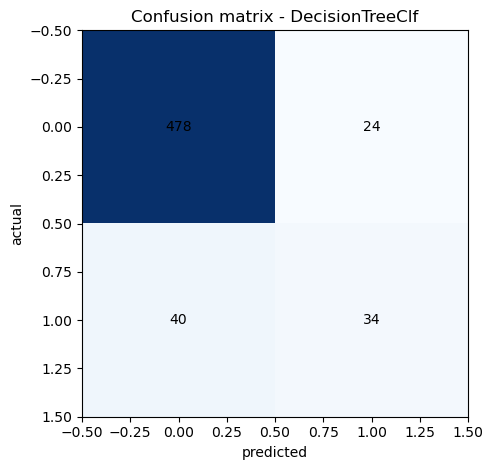

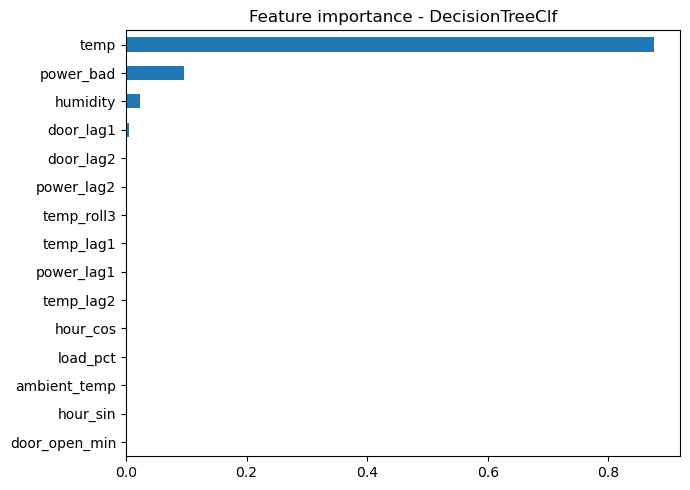

In [14]:
n = int(len(X) * 0.8)
Xtr, Xte = X.iloc[:n], X.iloc[n:]

# ---- best classifier -> confusion matrix + feature importance ----
clf = m[(m["task"] == "classification") & (~m["model"].str.startswith("Baseline"))]
best = clf.loc[clf["f1"].astype(float).idxmax()]
print("best classifier:", best["model"], "f1 =", best["f1"])
params = ast.literal_eval(best["best_params"])
ytr, yte = df["excursion"].iloc[:n], df["excursion"].iloc[n:]

if "RandomForest" in best["model"]:
    model = RandomForestClassifier(random_state=42, class_weight="balanced", **params)
elif "DecisionTree" in best["model"]:
    model = DecisionTreeClassifier(random_state=42, class_weight="balanced", **params)
elif "SVC" in best["model"]:
    model = Pipeline([("s", StandardScaler()),
                      ("m", SVC(class_weight="balanced",
                                C=params["m__C"], gamma=params["m__gamma"]))])
model.fit(Xtr, ytr)
pred = model.predict(Xte)

cm = confusion_matrix(yte, pred)
plt.figure()
plt.imshow(cm, cmap="Blues")
plt.title(f"Confusion matrix - {best['model']}")
plt.xlabel("predicted"); plt.ylabel("actual")
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")
plt.tight_layout(); plt.savefig("results/confusion_matrix.png")

if hasattr(model, "feature_importances_"):
    imp = pd.Series(model.feature_importances_, index=X.columns)
    plt.figure()
    imp.sort_values().plot(kind="barh", figsize=(7, 5))
    plt.title(f"Feature importance - {best['model']}")
    plt.tight_layout(); plt.savefig("results/feat_importance.png")
    print(imp.sort_values(ascending=False).round(3).head(6))

best regressor: LinearRegression rmse = 1.0374
plots saved in results/  (shown above)


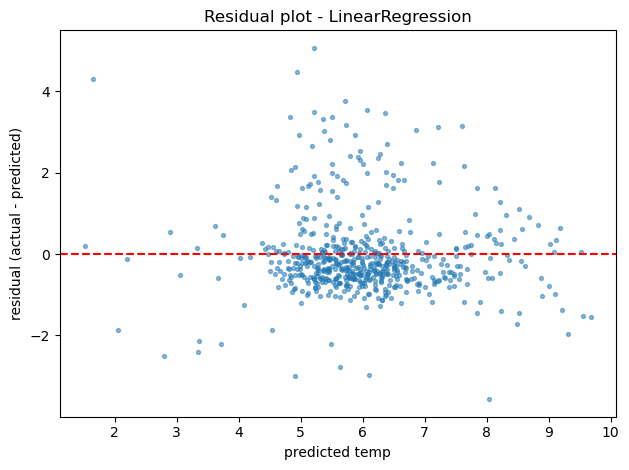

In [15]:
# ---- best regressor -> residual plot ----
reg = m[(m["task"] == "regression") & (~m["model"].str.startswith("Baseline"))]
best = reg.loc[reg["rmse"].astype(float).idxmin()]
print("best regressor:", best["model"], "rmse =", best["rmse"])
params = ast.literal_eval(best["best_params"])
ytr, yte = df["temp_next"].iloc[:n], df["temp_next"].iloc[n:]

rmodel = LinearRegression()
rmodel.fit(Xtr, ytr)
pred = rmodel.predict(Xte)

plt.figure()
plt.scatter(pred, yte - pred, s=8, alpha=0.5)
plt.axhline(0, color="r", ls="--")
plt.title(f"Residual plot - {best['model']}")
plt.xlabel("predicted temp"); plt.ylabel("residual (actual - predicted)")
plt.tight_layout(); plt.savefig("results/residuals.png")
print("plots saved in results/  (shown above)")